In [1]:
%pylab inline
import os
from astropy.table import Table, vstack
import astropy.io.fits as pyfits

import matplotlib
import matplotlib.patches as mpatches

from lsst.daf.persistence import Butler
butler18 = Butler('./homeDir/data/hsc_ssp/dr2/s18a/data/s18a_wide/')
skymap  =    butler18.get('deepCoadd_skyMap')

import lsst.afw.table as afwTable
import lsst.afw.image as afwImage
import lsst.afw.display as afwDisplay
#import lsst.afw.geom as afwGeom
import lsst.geom as afwGeom
from lsst.meas.base.noiseReplacer import NoiseReplacerConfig,NoiseReplacer
import lsst.analysis.deblender as deblender

import astropy.io.ascii as ascii
afwDisplay.setDefaultBackend('matplotlib')
plt.rcParams['figure.figsize'] = (15, 15)

def findInAperture(centList,radius,cat):
    """Return the objects within Aperture"""
    oneObjCatalog = afwTable.SourceCatalog(cat.getSchema())
    centroidName = cat.table.getCentroidDefinition()
    oneObjCatalog.table.defineCentroid(centroidName)

    for cent in centList:
        x, y = cent.getX(), cent.getY()
        s = oneObjCatalog.addNew()
        s.set("%s_x" % centroidName, x)
        s.set("%s_y" % centroidName, y)

    return afwTable.matchXy(cat, oneObjCatalog, radius)


Populating the interactive namespace from numpy and matplotlib


# ICG

In [11]:
# Preparing data
catNei=Table.read('./wrkDir/database/compare/ICG-neighbour-SDSS-undetect.csv')
catCen=Table.read('./wrkDir/database/compare/ICG_MW-central-20200316.csv')
if False:
    cids=np.unique(catNei['central_id'])
    catCen=catCen[cids-1]
    catCen['central_id']=cids
    catCen.write('./wrkDir/database/compare/ICG_MW-central-20200316.csv')

if False:
    catCen['tract']=None
    catCen['patch']=None
    for ss in catCen:
        centCoord=afwGeom.SpherePoint(afwGeom.Angle(ss['ra'],afwGeom.degrees),afwGeom.Angle(ss['dec'],afwGeom.degrees))
        TPinfo=skymap.findClosestTractPatchList([centCoord])[0]
        ss['tract']=TPinfo[0].getId()
        ss['patch']='%d,%d' %TPinfo[1][0].getIndex()
    catCen.write('./wrkdir/database/compare/icg_mw-central-20200316.csv')

if True:
    from astropy.cosmology import FlatLambdaCDM
    cosmo = FlatLambdaCDM(H0=67.3, Om0=0.315, Tcmb0=2.725)
    DD=cosmo.luminosity_distance(catCen['z']).value/(1.+catCen['z'])**2*1000.
    rPix20kpc=20/DD/np.pi*180.*3600./0.168
    catCen['rPix20kpc']=rPix20kpc
    catCen.write('./wrkDir/database/compare/ICG_MW-central-202004222012.csv')


In [12]:
msk1=(catCen['ra']>214.236)&(catCen['ra']<214.237)
print(catCen[msk1])
msk2=(catCen['ra']>189.256)&(catCen['ra']<189.257)
print(catCen[msk2])

   ra      dec      z       log_M   ... central_id tract patch     rPix20kpc    
-------- ------- -------- --------- ... ---------- ----- ----- -----------------
214.2369 -0.7823 0.125555 10.777541 ...        342  9371   7,4 50.95943085172383
   ra     dec      z       log_M   ... central_id tract patch     rPix20kpc    
-------- ------ -------- --------- ... ---------- ----- ----- -----------------
189.2565 0.9171 0.076498 10.788947 ...       1088  9597   6,5 79.01938324613808


In [18]:
help(afwDisplay.rgb)

Help on package lsst.afw.display.rgb in lsst.afw.display:

NAME
    lsst.afw.display.rgb

PACKAGE CONTENTS
    rgb
    rgbContinued

FUNCTIONS
    getZScale(...) method of builtins.PyCapsule instance
        getZScale(*args, **kwargs)
        Overloaded function.
        
        1. getZScale(image: lsst.afw.image.image.image.ImageU, nsamples: int=1000, contrast: float=0.25) -> Tuple[float, float]
        
        2. getZScale(image: lsst.afw.image.image.image.ImageF, nsamples: int=1000, contrast: float=0.25) -> Tuple[float, float]
    
    replaceSaturatedPixels(...) method of builtins.PyCapsule instance
        replaceSaturatedPixels(rim: lsst.afw.image.maskedImage.maskedImage.MaskedImageF, gim: lsst.afw.image.maskedImage.maskedImage.MaskedImageF, bim: lsst.afw.image.maskedImage.maskedImage.MaskedImageF, borderWidth: int=2, saturatedPixelValue: float=65535) -> None

FILE
    /work/xiangchong.li/lsstsw/stack/Linux64/afw/19.0.0-11-g3888aff52/python/lsst/afw/display/rgb/__init__.py




In [13]:
ssCen=catCen[msk2][0]
showR=ssCen['rPix20kpc']*10.
catUnMat=catNei[catNei['central_id']==ssCen['central_id']]

dataId = {'filter': 'HSC-R', 'tract': ssCen['tract'], 'patch': ssCen['patch']}
print(dataId)
exp18 = butler18.get('deepCoadd_calexp', **dataId)
src18=butler18.get('deepCoadd_meas',**dataId)

{'filter': 'HSC-R', 'tract': 9597, 'patch': '6,5'}


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)


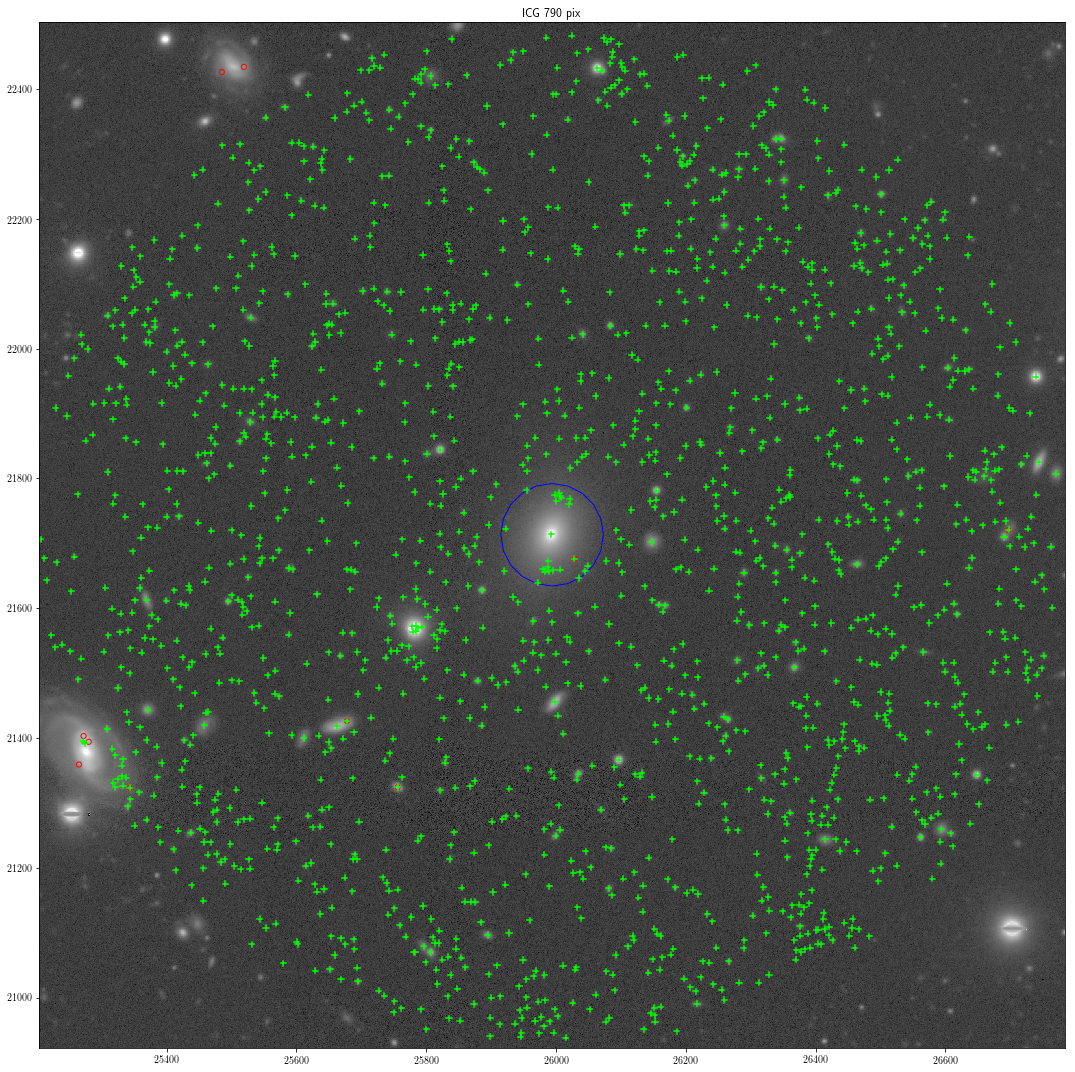

In [14]:
#Show all Galaxies

centCoord=afwGeom.SpherePoint(afwGeom.Angle(ssCen['ra'],afwGeom.degrees),afwGeom.Angle(ssCen['dec'],afwGeom.degrees))
wcs=exp18.getWcs()
centPoint=afwGeom.Point2I(wcs.skyToPixel(centCoord))

extU=afwGeom.Extent2I(showR,showR)
boxU=afwGeom.Box2I(centPoint-extU,2*extU)
boxU.clip(exp18.getBBox())
expShow=exp18[boxU]
display1 = afwDisplay.getDisplay(frame=1)
display1.setMaskTransparency(100)
#display1.scale("Asinh", "zscale")
display1.scale("asinh", "zscale")
display1.mtv(expShow,title='ICG %d pix' %(showR))

nameNchild = "deblend_nChild"
mIdList=[]
matched=findInAperture([centPoint],showR,src18)

with display1.Buffering(): 
    display1.dot('o',centPoint.getX(),centPoint.getY(), size=ssCen['rPix20kpc'], ctype=afwDisplay.BLUE) 
    for mm in matched:
        ssShow=mm[0]
        if ssShow[nameNchild]==0:
            label='+'
            display1.dot(label,ssShow.getX(),ssShow.getY(), size=4, ctype=afwDisplay.GREEN) 
            mIdList.append(ssShow.getId())
    for ssShow in catUnMat:
        raShow=ssShow['satellite_ra']
        decShow=ssShow['satellite_dec']
        cShow=afwGeom.SpherePoint(afwGeom.Angle(raShow,afwGeom.degrees),afwGeom.Angle(decShow,afwGeom.degrees))
        pShow=afwGeom.Point2I(wcs.skyToPixel(cShow)) 
        #print(pShow-centPoint)
        label='o'
        display1.dot(label,pShow.getX(),pShow.getY(), size=4, ctype=afwDisplay.RED) 

display1.savefig('./wrkDir/exfaGalAll/plot-brightObj/S18-ICG-ID-%d.png' %(ssCen['central_id']))


/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().

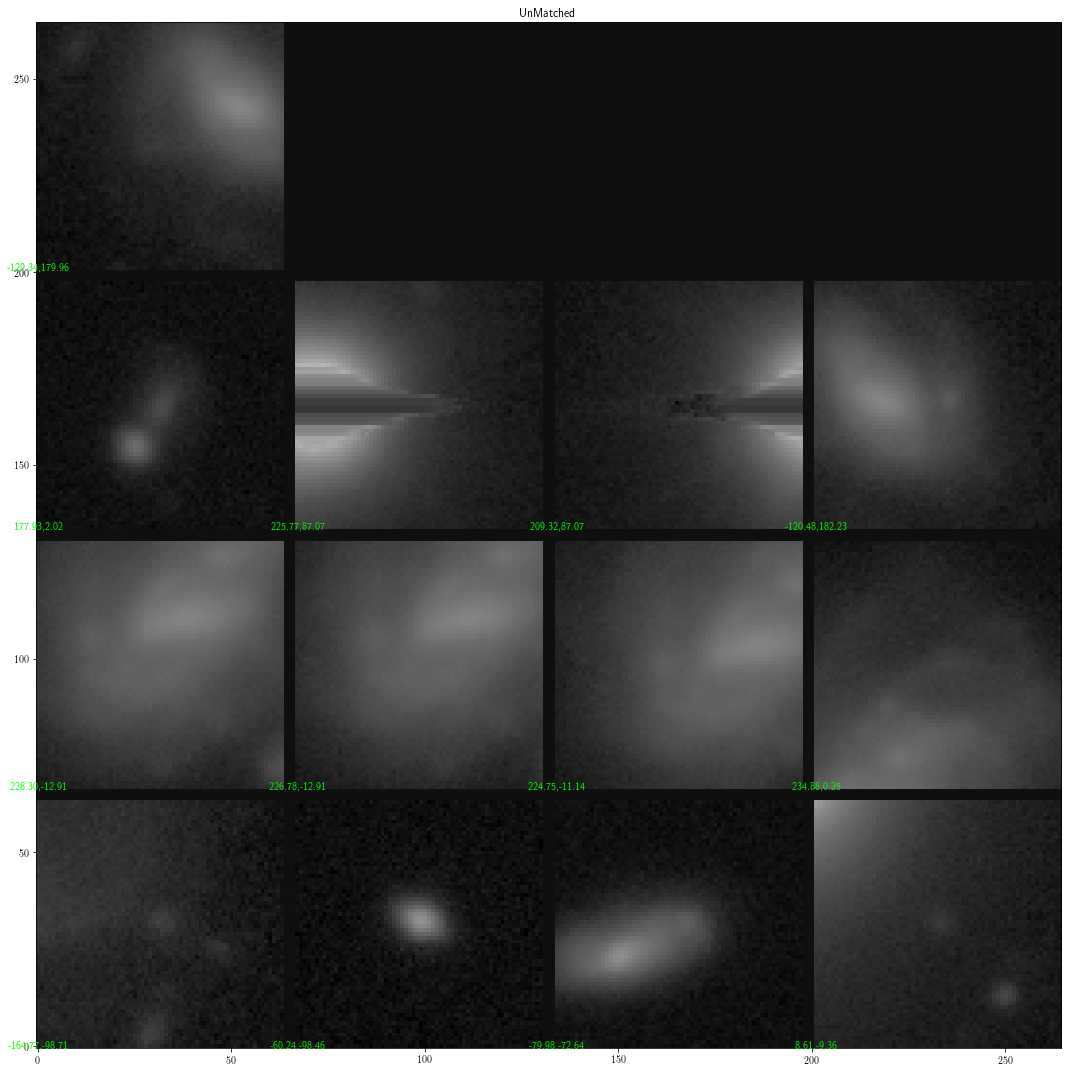

In [15]:
# Show Interested Galaxies
mos=afwDisplay.utils.Mosaic()
noiConfig   =   NoiseReplacerConfig()
fp18  = {measRecord.getId(): (measRecord.getParent(), measRecord.getFootprint())
              for measRecord in src18}
#nrper18=  NoiseReplacer(noiConfig, exp18, fp18)

display2 = afwDisplay.getDisplay(frame=3)
display2.setMaskTransparency(90)
#display2.scale("Asinh", "zscale")
display2.scale("asinh", "zscale")
ratio=20./ssCen['rPix20kpc']
for ssShow in catUnMat:
    raShow=ssShow['satellite_ra']
    decShow=ssShow['satellite_dec']
    cShow=afwGeom.SpherePoint(afwGeom.Angle(raShow,afwGeom.degrees),afwGeom.Angle(decShow,afwGeom.degrees))
    pShow=afwGeom.Point2I(wcs.skyToPixel(cShow)) 
    matched=findInAperture([pShow],4,src18)
    for mm in matched:
        ss=mm[0]
        if ss[nameNchild]==0:
            cc=afwGeom.Point2I(ss.getCentroid())
            dis=cc-centPoint
            label='%.2f,%.2f' %(dis.getX()*ratio,dis.getY()*ratio)
            boxU.clip(exp18.getBBox())
            extU=afwGeom.Extent2I(32,32)
            boxU=afwGeom.Box2I(cc-extU,2*extU)
            #nrper18.insertSource(ss.getId())
            imgShow=afwImage.MaskedImageF(boxU)
            imgShow.getImage().getArray()[:,:]=exp18.getImage()[boxU].getArray()[:,:]
            mos.append(imgShow,label=label)
            del imgShow
            #nrper18.removeSource(ss.getId())

mos.makeMosaic(display=display2,title='UnMatched')
display2.savefig('./wrkDir/exfaGalAll/plot-brightObj/S18-ICG-ID-%d-unMat.png' %(ssCen['central_id']))

/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().get("slot_Centroid")` instead. To be removed after 20.0.0.)
/work/xiangchong.li/lsstsw/miniconda/envs/lsst-scipipe/lib/python3.7/site-packages/ipykernel_launcher.py:28: FutureWarning: Call to deprecated method getCentroidDefinition. (Use `getSchema().getAliasMap().

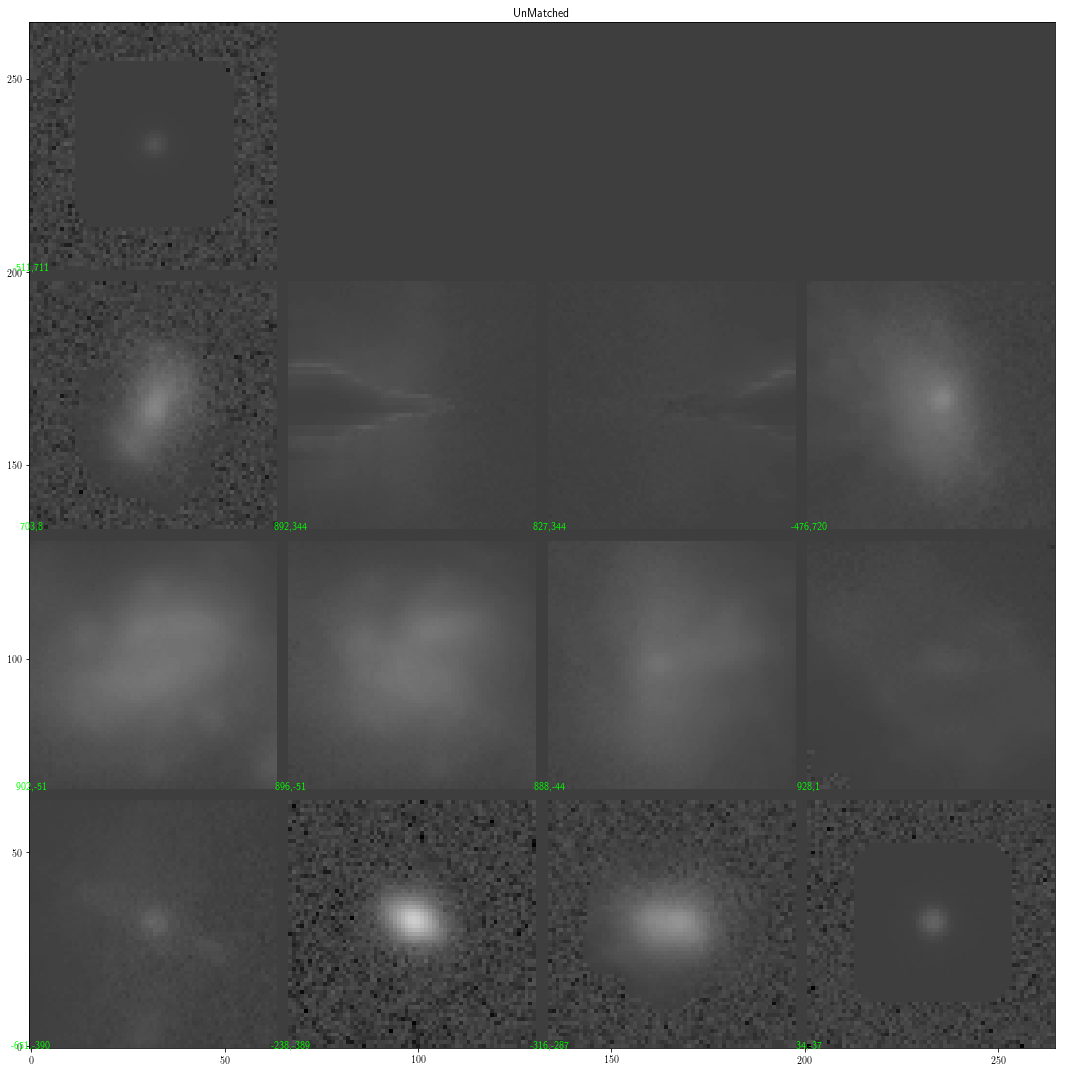

In [16]:
# Show Interested Galaxies
mos=afwDisplay.utils.Mosaic()
noiConfig   =   NoiseReplacerConfig()
fp18  = {measRecord.getId(): (measRecord.getParent(), measRecord.getFootprint())
              for measRecord in src18}
nrper18=  NoiseReplacer(noiConfig, exp18, fp18)

display3 = afwDisplay.getDisplay(frame=4)
display3.setMaskTransparency(90)
#display3.scale("Asinh", "zscale")
display3.scale("asinh", "zscale")

for ssShow in catUnMat:
    raShow=ssShow['satellite_ra']
    decShow=ssShow['satellite_dec']
    cShow=afwGeom.SpherePoint(afwGeom.Angle(raShow,afwGeom.degrees),afwGeom.Angle(decShow,afwGeom.degrees))
    pShow=afwGeom.Point2I(wcs.skyToPixel(cShow)) 
    matched=findInAperture([pShow],4,src18)
    for mm in matched:
        ss=mm[0]
        if ss[nameNchild]==0:
            cc=afwGeom.Point2I(ss.getCentroid())
            dis=cc-centPoint
            label='%d,%d' %(dis.getX(),dis.getY())
            boxU.clip(exp18.getBBox())
            extU=afwGeom.Extent2I(32,32)
            boxU=afwGeom.Box2I(cc-extU,2*extU)
            nrper18.insertSource(ss.getId())
            imgShow=afwImage.MaskedImageF(boxU)
            imgShow.getImage().getArray()[:,:]=exp18.getImage()[boxU].getArray()[:,:]
            mos.append(imgShow,label=label)
            del imgShow
            nrper18.removeSource(ss.getId())

mos.makeMosaic(display=display3,title='UnMatched')
display3.savefig('./wrkDir/exfaGalAll/plot-brightObj/S18-ICG-ID-%d-unMat-deblend.png' %(ssCen['central_id']))